# Pertemuan 07: Filter Digital FIR

**Praktikum pendamping kuliah 120 menit.** Bagaimana mengubah batas frekuensi yang diinginkan menjadi koefisien konvolusi, lalu memastikan filter memenuhi batas tersebut? Sembilan demo di bawah mengikuti contoh hitungan pada catatan kuliah. Jalankan sel persiapan sekali, lalu pilih demo atau gunakan **Run All**. Tidak ada berkas data yang perlu diunduh.

**Konvensi:** $N$ adalah jumlah tap; orde $N-1$. Frekuensi $f$ dalam Hz, $F_s$ frekuensi sampling, dan $\Omega=2\pi f/F_s$ dalam rad/sampel. Setiap gambar ditampilkan langsung di bawah sel. Fungsi **ukur** memeriksa pita tertutup, termasuk frekuensi tepi dan Nyquist.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from matplotlib.ticker import MaxNLocator

BIRU, JINGGA, HIJAU, UNGU = "#225598", "#B74D18", "#137569", "#784782"
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[BIRU, JINGGA, HIJAU, UNGU, "#555555"]),
                     "lines.linewidth": 1.7, "figure.facecolor": "white"})
np.set_printoptions(precision=6, suppress=True)

def selesai(fig, nama):
    """Tampilkan gambar pada keluaran sel ini."""
    plt.show()
    plt.close(fig)

def panel(nr=1, nc=2, ukuran=(10, 3.7)):
    return plt.subplots(nr, nc, figsize=ukuran, layout="constrained")

def batang(ax, n, x, warna=BIRU):
    ax.axhline(0, color="#666", lw=.8)
    ax.vlines(n, 0, x, color=warna, lw=1.6)
    ax.scatter(n, x, s=24, c=warna, zorder=3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

def db(z, lantai=-110):
    return 20*np.log10(np.maximum(np.abs(z), 10**(lantai/20)))

def respons(h, f, Fs):
    return signal.freqz(h, worN=f, fs=Fs)[1]

def ukur(h, Fs, pita_lolos, pita_henti):
    """Deviasi amplitudo dan atenuasi terburuk. Tepi semua pita disertakan."""
    semua = pita_lolos + pita_henti
    f = np.unique(np.r_[np.linspace(0, Fs/2, 50001), np.ravel(semua)])
    mag = np.abs(respons(h, f, Fs))
    def maks(pita, target):
        return max(np.max(np.abs(mag[(f >= lo) & (f <= hi)] - target))
                   for lo, hi in pita)
    dp, ds = maks(pita_lolos, 1.0), maks(pita_henti, 0.0)
    return dp, ds, -20*np.log10(ds)

def lp_ideal(m, nu_c):
    # np.sinc(v) = sin(pi*v)/(pi*v), dan np.sinc(0) = 1.
    return 2*nu_c*np.sinc(2*nu_c*m)

def lp_hamming(N):
    m = np.arange(N) - (N-1)/2
    return lp_ideal(m, 1750/8000) * np.hamming(N)

## 01 · Rata-rata tiga sampel
Tap $h=[1,1,1]/3$ membagi setiap sampel masukan ke tiga waktu keluaran. Hitung dahulu $y[1]=(6+3+0)/3$ dan $y[3]=(0+0+6)/3$, lalu bandingkan dengan konvolusi penuh pada gambar.

Masukan: [3. 6. 0. 0.]   Keluaran konvolusi penuh: [1. 3. 3. 2. 0. 0.]


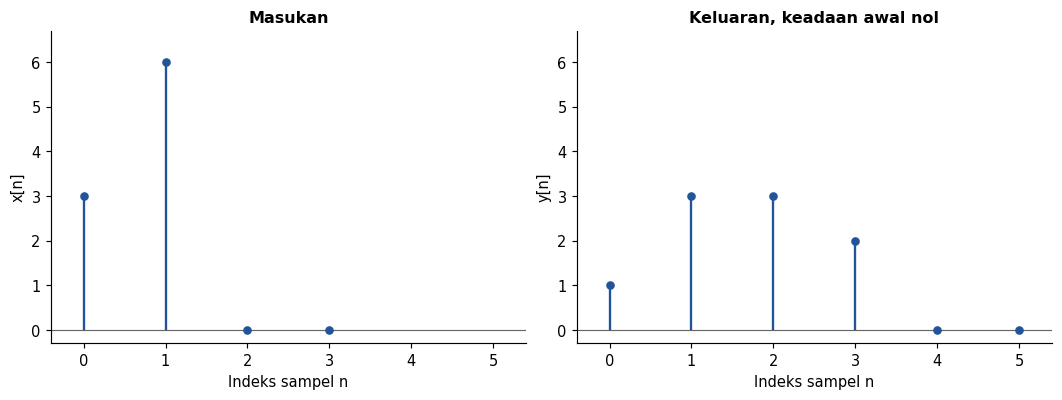

In [2]:
x = np.array([3., 6., 0., 0.])
h = np.ones(3)/3
y = np.convolve(x, h)
print("Masukan:", x, "  Keluaran konvolusi penuh:", y)
np.testing.assert_allclose(y, [1, 3, 3, 2, 0, 0])
fig, ax = panel()
for a, v, judul, label in zip(ax, [x, y], ["Masukan", "Keluaran, keadaan awal nol"], ["x[n]", "y[n]"]):
    batang(a, np.arange(len(v)), v)
    a.set(xlabel="Indeks sampel n", ylabel=label, xlim=(-.4, 5.4), ylim=(-.3, 6.7), title=judul)
selesai(fig, "01_konvolusi")

## 02 · Simetri, nol wajib, dan fase
Garis vertikal pada grafik tap adalah pusat $\alpha=(N-1)/2$. Bandingkan titik di DC dan Nyquist pada keempat tipe. Grafik kedua memisahkan cabang fase ketika respons melewati nol: perhatikan bahwa kemiringan dapat tetap sama pada kedua sisi lompatan.

Tipe I: |H(0)| = 9; |H(π)| = 1
Tipe II: |H(0)| = 6; |H(π)| = 0
Tipe III: |H(0)| = 0; |H(π)| = 0
Tipe IV: |H(0)| = 0; |H(π)| = 2


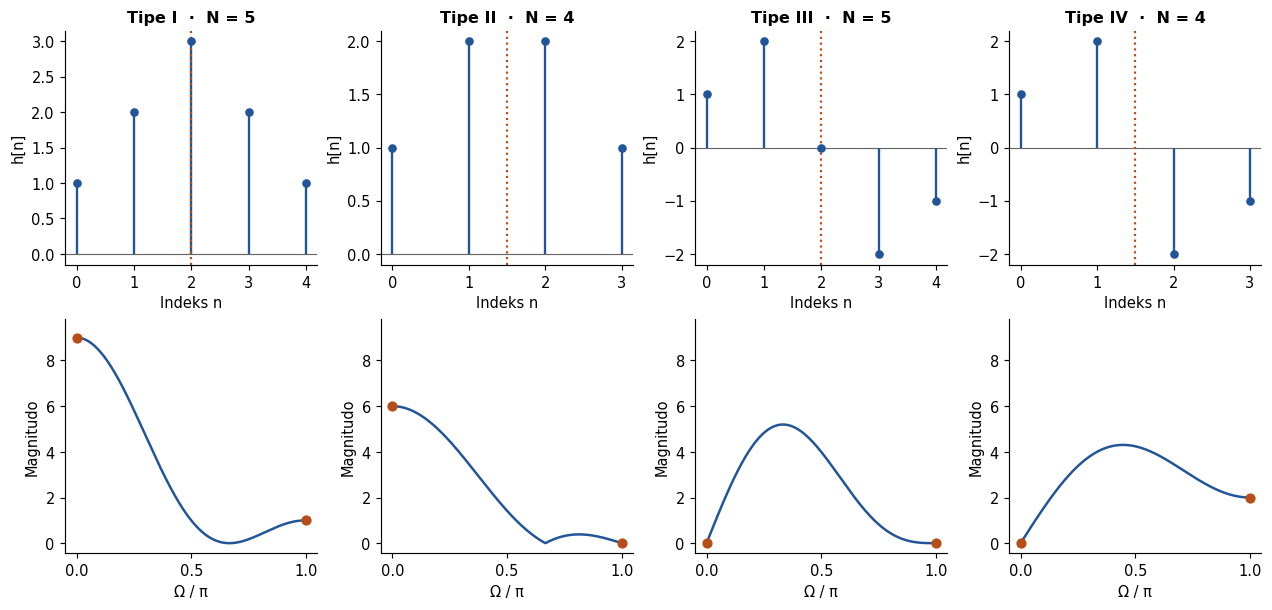

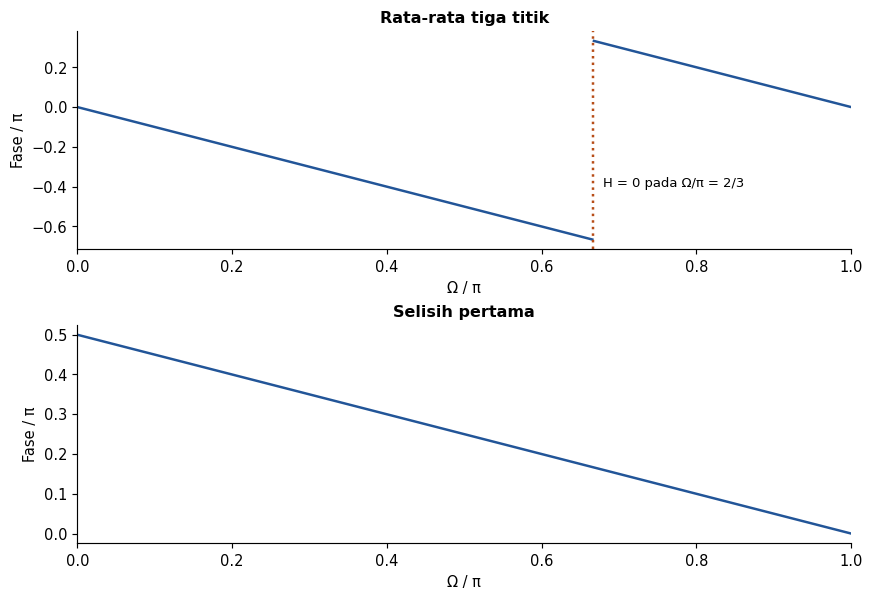

In [3]:
contoh = [("I", [1, 2, 3, 2, 1]), ("II", [1, 2, 2, 1]),
          ("III", [1, 2, 0, -2, -1]), ("IV", [1, 2, -2, -1])]
fig, ax = panel(2, 4, (12, 5.7))
r = np.linspace(0, 1, 801)
for j, (tipe, h) in enumerate(contoh):
    n = np.arange(len(h))
    batang(ax[0,j], n, h)
    ax[0,j].axvline((len(h)-1)/2, color=JINGGA, ls=":", lw=1.5)
    ax[0,j].set(title=f"Tipe {tipe}  ·  N = {len(h)}", xlabel="Indeks n", ylabel="h[n]")
    mag = np.abs(respons(h, r, 2))
    ax[1,j].plot(r, mag)
    ax[1,j].scatter([0, 1], mag[[0, -1]], color=JINGGA, zorder=3)
    ax[1,j].set(xlabel="Ω / π", ylabel="Magnitudo", xticks=[0,.5,1], ylim=(-.45,9.8))
    print(f"Tipe {tipe}: |H(0)| = {mag[0]:.0f}; |H(π)| = {mag[-1]:.0f}")
selesai(fig, "02_tipe_fir")

# Dua contoh fase. Pisahkan pita agar garis tidak melintasi nol spektral.
fig, ax = panel(2,1,(8.2,5.6))
for i,(koef,judul) in enumerate([([1/3]*3,"Rata-rata tiga titik"),([1,-1],"Selisih pertama")]):
    for rr in ([np.linspace(.001,2/3-.001,310),np.linspace(2/3+.001,1,180)]
               if i==0 else [np.linspace(.001,1,450)]):
        fase=np.unwrap(np.angle(respons(koef,rr,2)))
        ax[i].plot(rr,fase/np.pi,color=BIRU)
    if i==0:
        ax[i].axvline(2/3,ls=":",color=JINGGA)
        ax[i].text(.68,-.40,"H = 0 pada Ω/π = 2/3",fontsize=9)
    ax[i].set(xlabel="Ω / π",ylabel="Fase / π",title=judul,xlim=(0,1))
selesai(fig, "02b_fase")

## 03 · Baca masker sebelum mendesain
Kalikan tepi ternormalisasi dengan 10 kHz. Daerah berwarna pucat adalah transisi; target deviasi hanya berlaku di pita lolos dan kedua pita henti. Di pita henti besaran 0,001 adalah amplitudo, setara dengan atenuasi 60 dB.

Tepi (Hz): [1400. 1800. 3300. 3700.]
Atenuasi (dB): 60.0 Batas atas (dB): 0.42378598139876184


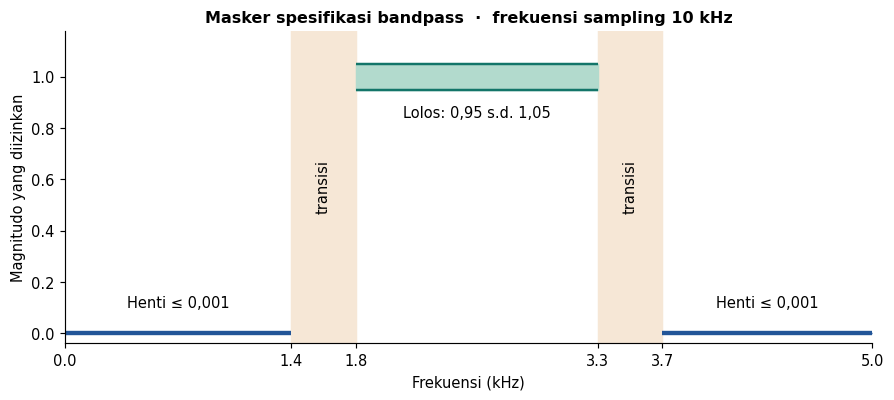

In [4]:
Fs = 10000
fig, ax = panel(1, 1, (8.4, 3.7))
for lo, hi in [(0, 1.4), (3.7, 5)]:
    ax.fill_between([lo, hi], 0, .001, color=BIRU)
    ax.hlines(.001, lo, hi, color=BIRU, lw=3)
for lo, hi in [(1.4,1.8),(3.3,3.7)]:
    ax.axvspan(lo, hi, color="#f6e7d6")
ax.fill_between([1.8,3.3], .95, 1.05, color="#b2dacd")
ax.hlines([.95,1.05], 1.8, 3.3, color=HIJAU)
ax.text(2.55,.84,"Lolos: 0,95 s.d. 1,05",ha="center")
ax.text(.7,.10,"Henti ≤ 0,001", ha="center")
ax.text(4.35,.10,"Henti ≤ 0,001", ha="center")
ax.text(1.6,.48,"transisi", ha="center",rotation=90)
ax.text(3.5,.48,"transisi", ha="center",rotation=90)
ax.set(xlabel="Frekuensi (kHz)", ylabel="Magnitudo yang diizinkan",
       xlim=(0,5), ylim=(-.04,1.18), xticks=[0,1.4,1.8,3.3,3.7,5],
       title="Masker spesifikasi bandpass  ·  frekuensi sampling 10 kHz")
print("Tepi (Hz):", np.array([.14,.18,.33,.37])*Fs)
print("Atenuasi (dB):", -20*np.log10(.001), "Batas atas (dB):",20*np.log10(1.05))
selesai(fig, "03_spesifikasi")

## 04 · Mengapa bentuk jendela penting?
Semua jendela di bawah sama panjang. Bandingkan lebar puncak di sekitar DC dengan tinggi lobus di sebelahnya. Grafik kanan adalah spektrum **jendela**, belum merupakan respons filter lowpass.

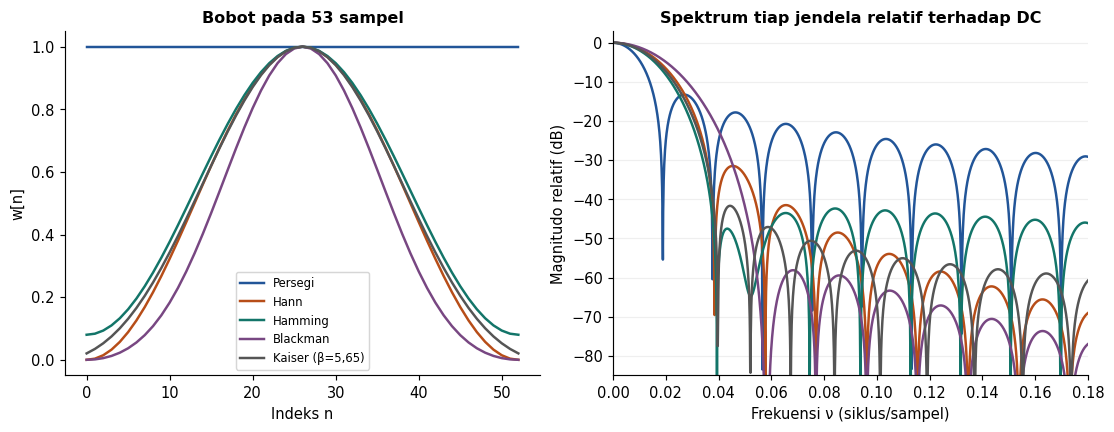

In [5]:
N = 53
n = np.arange(N)
nu = np.linspace(0,.18,1801)
jendela = {"Persegi": np.ones(N), "Hann": np.hanning(N), "Hamming": np.hamming(N),
           "Blackman": np.blackman(N), "Kaiser (β=5,65)": np.kaiser(N,5.65)}
fig, ax = panel(1,2,(10.5,4))
for nama, w in jendela.items():
    ax[0].plot(n,w,label=nama)
    ax[1].plot(nu,db(respons(w,nu,1)/w.sum()),label=nama)
ax[0].set(xlabel="Indeks n",ylabel="w[n]",title="Bobot pada 53 sampel")
ax[1].set(xlabel="Frekuensi ν (siklus/sampel)",ylabel="Magnitudo relatif (dB)",
          title="Spektrum tiap jendela relatif terhadap DC",xlim=(0,.18),ylim=(-85,3))
ax[0].legend(fontsize=8)
ax[1].grid(axis="y",alpha=.2)
selesai(fig, "04_jendela")

## 05 · Uji perkiraan panjang Hamming
Untuk 1.500 Hz sebagai tepi lolos dan 2.000 Hz sebagai tepi henti, cutoff idealnya 1.750 Hz. Bandingkan hasil ukur 53 dan 55 tap terhadap target 50 dB. Tap pertama yang dicetak adalah tap pusat, bukan tap indeks nol.

N=53: tiga tap dari pusat = [0.4375   0.311147 0.060092]; deviasi lolos=0.003764; As=47.659 dB
N=55: tiga tap dari pusat = [0.4375   0.311223 0.060151]; deviasi lolos=0.001927; As=52.289 dB


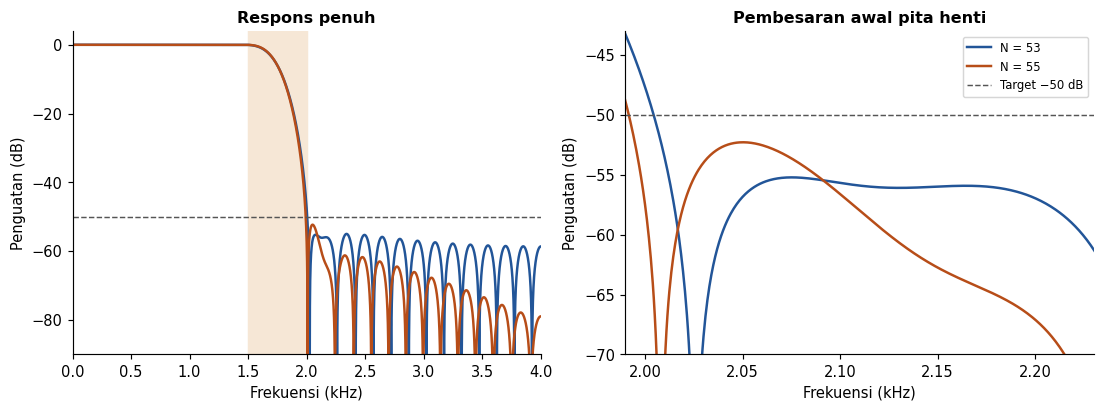

In [6]:
Fs = 8000
f = np.linspace(0,Fs/2,8001)
fig, ax = panel(1,2,(10.4,3.8))
for N in [53,55]:
    h = lp_hamming(N)
    np.testing.assert_allclose(h,signal.firwin(N,1750,fs=Fs,scale=False),atol=1e-14)
    d_p, d_s, A_s = ukur(h,Fs,[(0,1500)],[(2000,4000)])
    print(f"N={N}: tiga tap dari pusat = {h[N//2:N//2+3]}; deviasi lolos={d_p:.6f}; As={A_s:.3f} dB")
    v = db(respons(h,f,Fs))
    for a in ax: a.plot(f/1000,v,label=f"N = {N}")
ax[0].axvspan(1.5,2, color="#f6e7d6", zorder=-1)
for a in ax:
    a.axhline(-50,color="#555",ls="--",lw=1,label="Target −50 dB")
    a.set(xlabel="Frekuensi (kHz)",ylabel="Penguatan (dB)")
ax[0].set(title="Respons penuh",xlim=(0,4),ylim=(-90,4))
ax[1].set(title="Pembesaran awal pita henti",xlim=(1.99,2.23),ylim=(-70,-43))
ax[1].legend(fontsize=8)
selesai(fig, "05_hamming")

## 06 · Kaiser: lowpass dan bandpass
Pemilihan $\beta$ mengatur kompromi lobus utama dan lobus samping. Tepi ideal bandpass adalah 125 dan 275 Hz; nilai pusat seharusnya $2(275-125)/1000=0{,}3$. Di panel lowpass, satuan sumbu adalah $\Omega/\pi$. Bandingkan atenuasi aktual dengan garis target.

kaiserord: N=74, β=5.65326; contoh tipe I memakai N ganjil.
N=75: h[α]=0.30000; δp terukur=0.001331; δs terukur=0.001009; As=59.92 dB
N=87: h[α]=0.30000; δp terukur=0.001123; δs terukur=0.000907; As=60.85 dB
kaiserord: N=24, β=3.39532; contoh tipe I memakai N ganjil.
N=25: h[α]=0.40000; δp terukur=0.007718; δs terukur=0.008259; As=41.66 dB


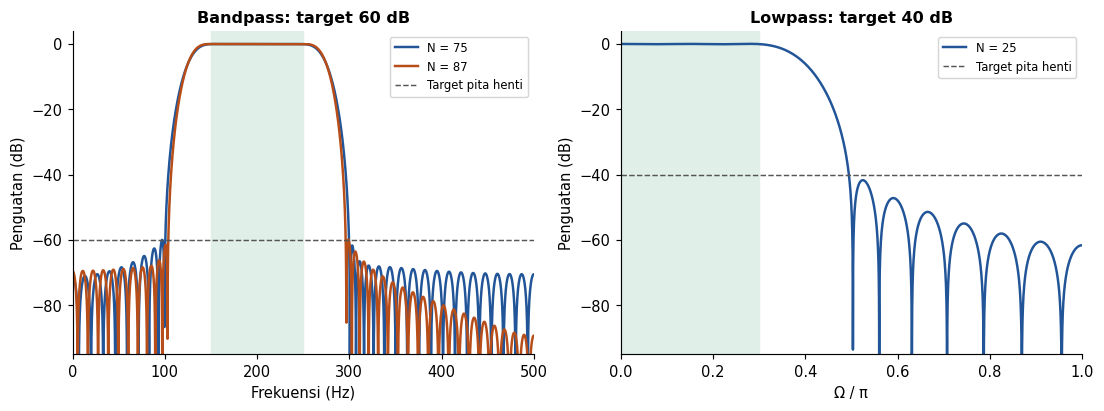

In [7]:
fig, ax = panel(1,2,(10.4,3.8))
for a, Fs, batas, lolos, henti, A, lebar, Ns, judul in [
    (ax[0],1000,[125,275],[(150,250)],[(0,100),(300,500)],60,.1,[75,87],"Bandpass: target 60 dB"),
    (ax[1],2,.4,[(0,.3)],[(.5,1)],40,.2,[25],"Lowpass: target 40 dB")]:
    n0,beta = signal.kaiserord(A,lebar)
    print(f"kaiserord: N={n0}, β={beta:.5f}; contoh tipe I memakai N ganjil.")
    f = np.linspace(0,Fs/2,4001)
    for lo,hi in lolos: a.axvspan(lo,hi,color="#e0f0e9",zorder=-1)
    for N in Ns:
        h = signal.firwin(N,batas,fs=Fs,pass_zero=(Fs==2),window=("kaiser",beta),scale=False)
        d_p,d_s,A_s = ukur(h,Fs,lolos,henti)
        print(f"N={N}: h[α]={h[N//2]:.5f}; δp terukur={d_p:.6f}; δs terukur={d_s:.6f}; As={A_s:.2f} dB")
        a.plot(f,db(respons(h,f,Fs)),label=f"N = {N}")
    a.axhline(-A,color="#555",ls="--",lw=1,label="Target pita henti")
    a.set(xlabel="Frekuensi (Hz)" if Fs==1000 else "Ω / π", ylabel="Penguatan (dB)",
          title=judul,ylim=(-95,4),xlim=(0,Fs/2))
    a.legend(fontsize=8)
selesai(fig, "06_kaiser")

## 07 · Galat berbobot dan riak
Target bandpass 1.000 hingga 1.500 Hz dirancang dua kali. Galat dihitung setelah faktor fase linear dilepas, sehingga amplitudo bertanda dipertahankan. Bandingkan rasio riak **sebelum** pembobotan (hasil cetak) dengan tinggi riak **setelah** pembobotan (grafik).

Bobot 1:1, deviasi lolos=0.011563, deviasi henti=0.011562, rasio=1.000
Bobot 5:1, deviasi lolos=0.020205, deviasi henti=0.004043, rasio=4.997


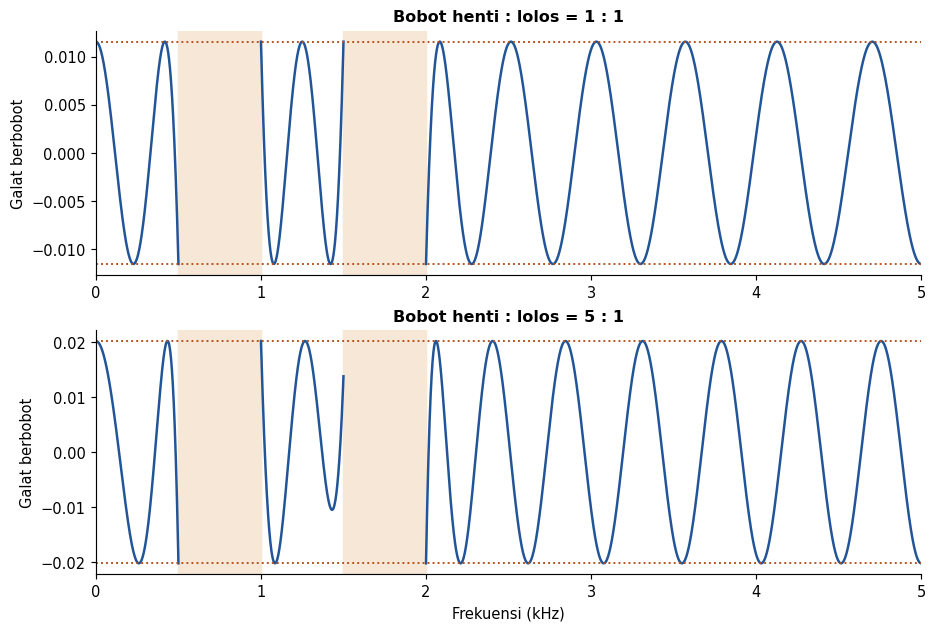

In [8]:
Fs, N = 10000, 41
tepi = [0,500,1000,1500,2000,5000]
f = np.linspace(0,Fs/2,10001)
fig,ax = panel(2,1,(8.8,5.9))
for a,ws in zip(ax,[1,5]):
    h = signal.remez(N,tepi,[0,1,0],weight=[ws,1,ws],fs=Fs,grid_density=64)
    H = respons(h,f,Fs)
    R = np.real(H*np.exp(2j*np.pi*f*(N-1)/(2*Fs)))
    d_p,d_s,A_s = ukur(h,Fs,[(1000,1500)],[(0,500),(2000,5000)])
    for lo,hi,D,W in [(0,500,0,ws),(1000,1500,1,1),(2000,5000,0,ws)]:
        mask = (f>=lo)&(f<=hi)
        a.plot(f[mask]/1000,W*(D-R[mask]),color=BIRU)
    for lo,hi in [(.5,1),(1.5,2)]: a.axvspan(lo,hi,color="#f6e7d6")
    for nilai in [d_p,-d_p]: a.axhline(nilai,color=JINGGA,ls=":",lw=1.3)
    a.set(title=f"Bobot henti : lolos = {ws} : 1",ylabel="Galat berbobot",xlim=(0,5))
    print(f"Bobot {ws}:1, deviasi lolos={d_p:.6f}, deviasi henti={d_s:.6f}, rasio={d_p/d_s:.3f}")
ax[-1].set_xlabel("Frekuensi (kHz)")
selesai(fig, "07_equiripple")

## 08 · Dari sembilan sampel spektrum ke tap
Jarak antartitik rancangan 2 kHz. Lima titik yang lolos adalah DC, ±2 kHz, dan ±4 kHz. Beri fase tunda empat sampel, lakukan IDFT, lalu periksa bahwa DFT mengembalikan semua sampel awal. Amati riak pada frekuensi di antara titik rancangan.

Koefisien kausal: [ 0.072523 -0.111111 -0.059121  0.319932  0.555556  0.319932 -0.059121
 -0.111111  0.072523]


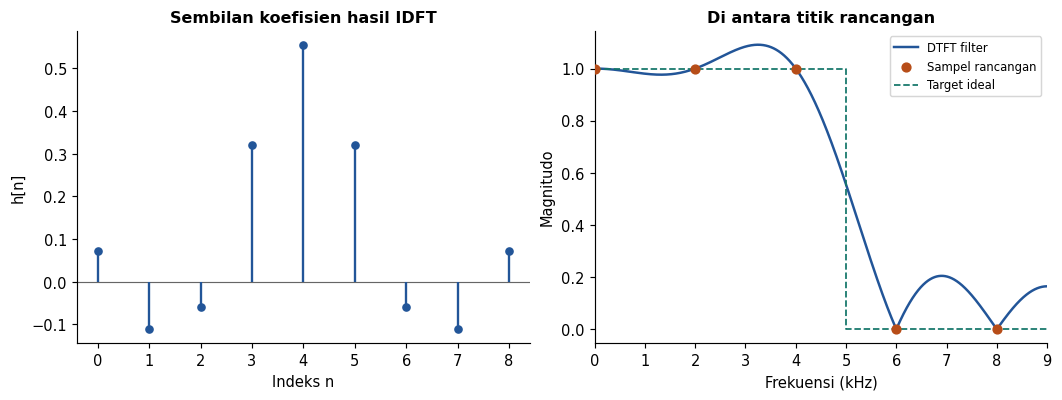

In [9]:
N,Fs = 9,18000
alpha = (N-1)/2
fk = np.fft.fftfreq(N, d=1/Fs)
D = (np.abs(fk)<=5000).astype(float)
Hk = D*np.exp(-2j*np.pi*fk*alpha/Fs)
hc = np.fft.ifft(Hk)
assert np.max(np.abs(hc.imag))<1e-12
h = hc.real
np.testing.assert_allclose(np.fft.fft(h),Hk,atol=1e-12)
np.testing.assert_allclose(h,h[::-1],atol=1e-12)
print("Koefisien kausal:", h)
fig,ax = panel()
batang(ax[0],np.arange(N),h)
ax[0].set(title="Sembilan koefisien hasil IDFT",xlabel="Indeks n",ylabel="h[n]")
f = np.linspace(0,Fs/2,3001)
ax[1].plot(f/1000,np.abs(respons(h,f,Fs)),label="DTFT filter")
ax[1].scatter(fk[fk>=0]/1000,D[fk>=0],color=JINGGA,zorder=3,label="Sampel rancangan")
ax[1].step([0,5,9],[1,0,0],where="post",color=HIJAU,ls="--",lw=1.2,label="Target ideal")
ax[1].set(xlabel="Frekuensi (kHz)",ylabel="Magnitudo",title="Di antara titik rancangan",xlim=(0,9))
ax[1].legend(fontsize=8)
selesai(fig, "08_sampling")

## 09 · Pindahkan lowpass ke Nyquist
Mengalikan tap dengan $(-1)^n$ menggeser spektrum setengah frekuensi sampling. Prediksi keluaran saat dua filter diberi jumlah nada 500 dan 3.000 Hz. Di akhir sel, hasil konvolusi sesudah transien diuji terhadap prediksi sinusoidal analitik.

Amplitudo keluaran untuk 500 dan 3000 Hz: [1.000333 0.000029]
Amplitudo keluaran untuk 500 dan 3000 Hz: [0.000205 0.600946]


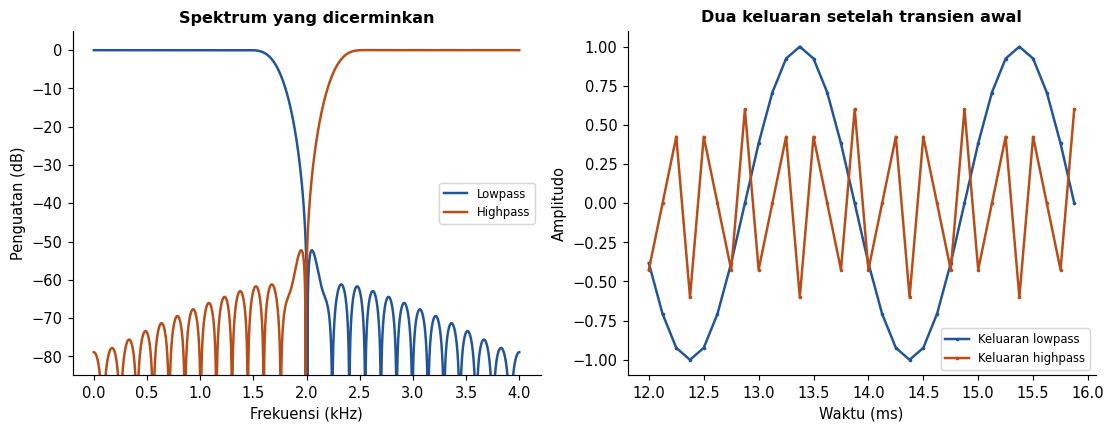

In [10]:
Fs,N = 8000,55
n = np.arange(N)
hl = lp_hamming(N)
hh = (-1.)**n*hl
f = np.linspace(0,Fs/2,4001)
HL, HH = respons(hl,f,Fs),respons(hh,f,Fs)
np.testing.assert_allclose(np.abs(HH),np.abs(HL[::-1]),atol=1e-12)
t = np.arange(240)/Fs
x = np.cos(2*np.pi*500*t)+.6*np.cos(2*np.pi*3000*t)
yl, yh = signal.lfilter(hl,[1],x),signal.lfilter(hh,[1],x)
fig,ax = panel(1,2,(10.5,4))
for z,label in [(HL,"Lowpass"),(HH,"Highpass")]: ax[0].plot(f/1000,db(z),label=label)
ax[0].set(xlabel="Frekuensi (kHz)",ylabel="Penguatan (dB)",title="Spektrum yang dicerminkan",ylim=(-85,5))
tampil = (t>=.012)&(t<.016)
for z,label in [(yl,"Keluaran lowpass"),(yh,"Keluaran highpass")]:
    ax[1].plot(1e3*t[tampil],z[tampil],".-",label=label,ms=3)
ax[1].set(xlabel="Waktu (ms)",ylabel="Amplitudo", title="Dua keluaran setelah transien awal")
for a in ax: a.legend(fontsize=8)
for taps in (hl,hh):
    G=respons(taps,np.array([500,3000]),Fs)
    # Keluaran keadaan tunak dihitung langsung dengan sifat eigenfungsi sinusoid.
    pred=np.real(G[0]*np.exp(2j*np.pi*500*t)+.6*G[1]*np.exp(2j*np.pi*3000*t))
    np.testing.assert_allclose(signal.lfilter(taps,[1],x)[N-1:],pred[N-1:],atol=1e-12)
    print("Amplitudo keluaran untuk 500 dan 3000 Hz:",np.abs(G)*[1,.6])
selesai(fig, "09_transformasi")

**Percobaan lanjutan:** ubah panjang Hamming dari 55 menjadi 57, lalu lihat apakah menambah dua tap selalu memperbaiki atenuasi. Daftar lengkap latihan hitungan dan pemrograman tersedia di catatan kuliah.